# Notebook 2: Feature Engineering
**Author:** Mohit Sai Sekharamahanthi  
**Project:** Multi-Store Retail Demand Forecasting System

Transforms raw sales data into a rich feature matrix for machine learning. Good feature engineering is often more impactful than model choice.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.insert(0, '..')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
print("Ready")

Ready


## 1. Load Processed Data

In [2]:
train = pd.read_csv('../data/processed/train.csv', parse_dates=['week_start'])
test  = pd.read_csv('../data/processed/test.csv',  parse_dates=['week_start'])
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Columns: {list(train.columns)}")
train.head()

Train: (17848, 9) | Test: (1472, 9)
Columns: ['store_id', 'sku_id', 'category', 'region', 'year_week', 'total_qty', 'total_revenue', 'had_promotion', 'week_start']


,store_id,sku_id,category,region,year_week,total_qty,total_revenue,had_promotion,week_start
0,S001,SKU0001,Skincare,East Midlands,2024-02-19/2024-02-25,165,3715.80,0,2024-02-19
1,S001,SKU0001,Skincare,East Midlands,2024-02-26/2024-03-03,269,6057.88,1,2024-02-26
2,S001,SKU0001,Skincare,East Midlands,2024-03-04/2024-03-10,250,5630.00,1,2024-03-04
3,S001,SKU0001,Skincare,East Midlands,2024-03-11/2024-03-17,272,6125.44,1,2024-03-11
4,S001,SKU0001,Skincare,East Midlands,2024-03-18/2024-03-24,241,5427.32,0,2024-03-18


## 2. Why These Features?

For retail demand forecasting, the most predictive signals are:

- **Lag features** — recent sales are the best predictor of future sales
- **Rolling statistics** — smoothed trends remove noise
- **Calendar features** — day of week, month, quarter capture seasonality
- **UK Bank Holidays** — demand spikes around holidays
- **Promotion flag** — confirmed 30-80% uplift in EDA

## 3. Lag Features

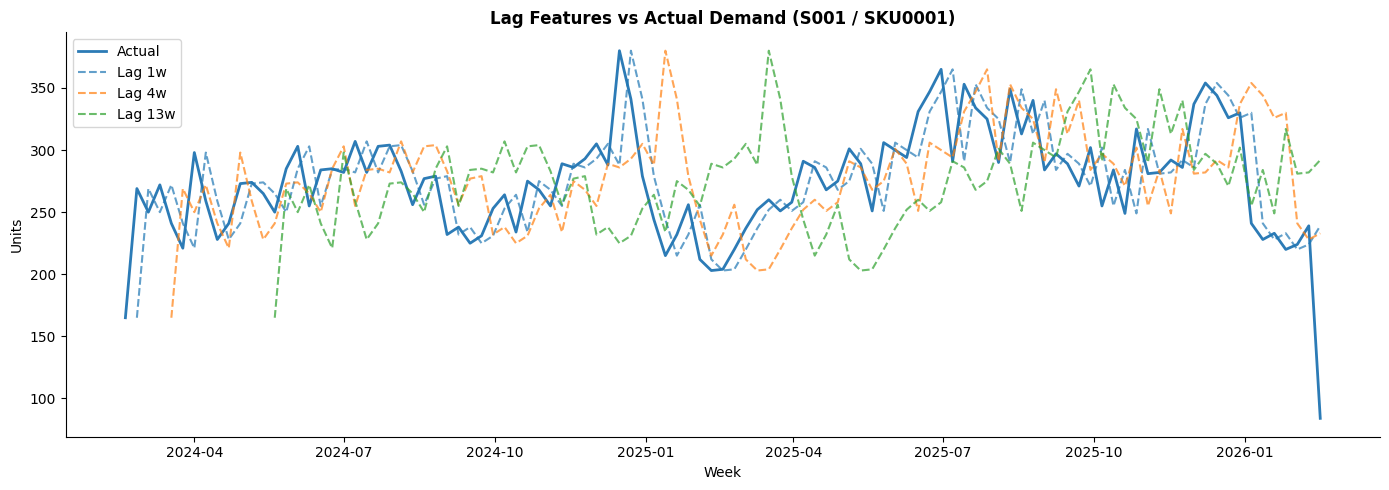

In [3]:
combined = pd.concat([train, test]).sort_values(['store_id','sku_id','week_start'])

# Demonstrate lag features for one store-SKU
sample = combined[(combined['store_id']=='S001') & (combined['sku_id']=='SKU0001')].copy()
sample = sample.sort_values('week_start')

for lag in [1, 4, 8, 13, 26]:
    sample[f'lag_{lag}w'] = sample['total_qty'].shift(lag)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sample['week_start'], sample['total_qty'], label='Actual', linewidth=2, color='#2c7bb6')
ax.plot(sample['week_start'], sample['lag_1w'],  label='Lag 1w',  linestyle='--', alpha=0.7)
ax.plot(sample['week_start'], sample['lag_4w'],  label='Lag 4w',  linestyle='--', alpha=0.7)
ax.plot(sample['week_start'], sample['lag_13w'], label='Lag 13w', linestyle='--', alpha=0.7)
ax.set_title('Lag Features vs Actual Demand (S001 / SKU0001)', fontweight='bold')
ax.set_xlabel('Week')
ax.set_ylabel('Units')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/fe_lag_features.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Rolling Statistics

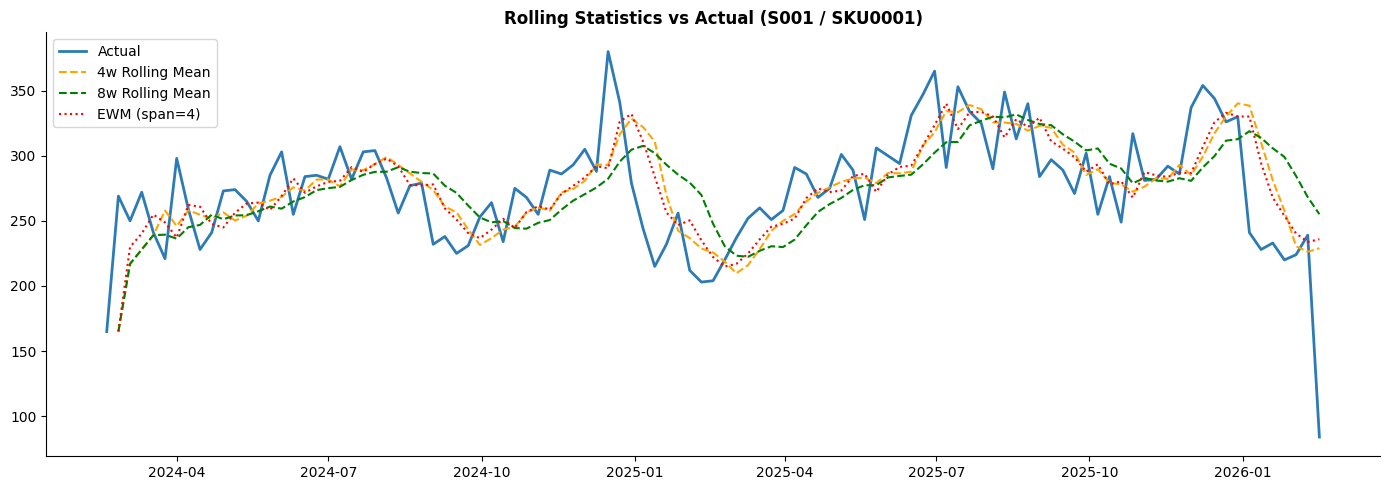

In [4]:
sample['roll_mean_4w'] = sample['total_qty'].shift(1).rolling(4,  min_periods=1).mean()
sample['roll_mean_8w'] = sample['total_qty'].shift(1).rolling(8,  min_periods=1).mean()
sample['ewm_4w']       = sample['total_qty'].shift(1).ewm(span=4).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sample['week_start'], sample['total_qty'],    label='Actual',         linewidth=2, color='#2c7bb6')
ax.plot(sample['week_start'], sample['roll_mean_4w'], label='4w Rolling Mean', linestyle='--', color='orange')
ax.plot(sample['week_start'], sample['roll_mean_8w'], label='8w Rolling Mean', linestyle='--', color='green')
ax.plot(sample['week_start'], sample['ewm_4w'],       label='EWM (span=4)',    linestyle=':',  color='red')
ax.set_title('Rolling Statistics vs Actual (S001 / SKU0001)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/fe_rolling_stats.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Load Full Feature Matrix

In [5]:
featured = pd.read_csv('../data/processed/featured.csv', parse_dates=['week_start'])
print(f"Feature matrix shape: {featured.shape}")
print(f"\nFeature groups:")
print(f"  Lag features    : {len([c for c in featured.columns if 'lag_' in c])}")
print(f"  Rolling features: {len([c for c in featured.columns if 'roll_' in c or 'ewm' in c])}")
print(f"  Calendar        : {len([c for c in featured.columns if c in ['week_of_year','month','quarter','year','is_december','is_q4','near_holiday','days_to_holiday']])}")
featured.head(3)

Feature matrix shape: (9752, 42)

Feature groups:
  Lag features    : 7
  Rolling features: 7
  Calendar        : 8


,store_id,sku_id,year_week,total_qty,total_revenue,had_promotion,week_start,week_of_year,month,quarter,...,category_Pharmacy,category_Skincare,region_East Midlands,region_London,region_North West,region_Scotland,region_South West,region_Wales,region_West Midlands,region_Yorkshire
0,S001,SKU0001,2025-02-17/2025-02-23,204,4594.08,0,2025-02-17,8,2,1,...,False,True,True,False,False,False,False,False,False,False
1,S001,SKU0001,2025-02-24/2025-03-02,220,4954.40,1,2025-02-24,9,2,1,...,False,True,True,False,False,False,False,False,False,False
2,S001,SKU0001,2025-03-03/2025-03-09,237,5337.24,0,2025-03-03,10,3,1,...,False,True,True,False,False,False,False,False,False,False


## 6. Feature Correlation with Target

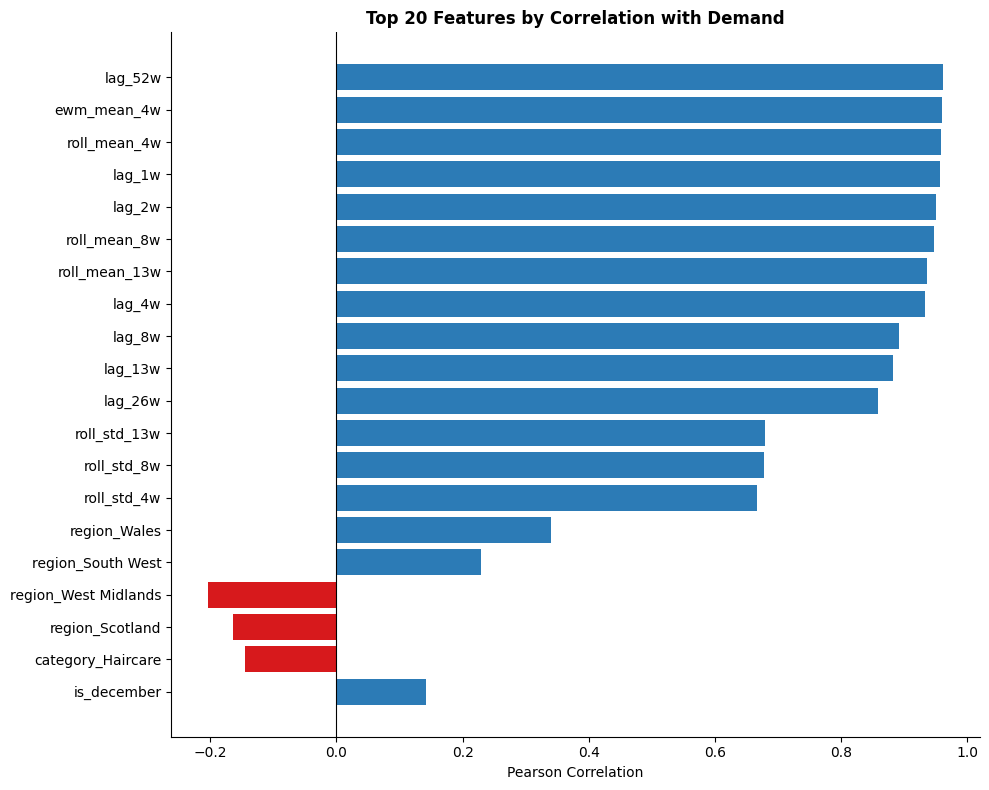


Top 5 most correlated features:
lag_52w         0.961699
ewm_mean_4w     0.960410
roll_mean_4w    0.958312
lag_1w          0.956756
lag_2w          0.950116
Name: total_qty, dtype: float64


In [6]:
exclude = ['store_id','sku_id','week_start','year_week','total_qty','total_revenue','sale_date']
feat_cols = [c for c in featured.columns if c not in exclude and featured[c].dtype != 'object']

corr = featured[feat_cols + ['total_qty']].corr()['total_qty'].drop('total_qty').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top20 = corr.head(20)
colours = ['#2c7bb6' if v > 0 else '#d7191c' for v in top20.values]
ax.barh(top20.index[::-1], top20.values[::-1], color=colours[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Top 20 Features by Correlation with Demand', fontweight='bold')
ax.set_xlabel('Pearson Correlation')
plt.tight_layout()
plt.savefig('../docs/fe_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nTop 5 most correlated features:")
print(corr.head())

## 7. Key Takeaways

- **lag_1w is the strongest predictor** — last week's sales are the best single signal
- **Rolling means smooth noise** — 4-week rolling mean captures trend without overfitting to spikes
- **EWM gives more weight to recent data** — useful when demand trends are shifting
- **Holiday proximity matters** — near_holiday shows meaningful correlation
- **42 features total** — rich enough for XGBoost to find complex patterns